# Football Player Detection & Match Analytics with YOLOv8

**Shubham Tanna**

This notebook takes broadcast frames from Bundesliga matches and turns them into match information:

1. **Detect** the ball, goalkeepers, outfield players and referees in every frame, using a YOLOv8-nano model fine-tuned on 298 labelled frames.
2. **Evaluate** the model honestly on a held-out test split, class by class.
3. **Analyse**: split players into teams by jersey colour, and estimate which team is in possession of the ball in each frame.

| | |
|---|---|
| Model | Ultralytics YOLOv8n (3.0M parameters), COCO-pretrained, fine-tuned |
| Data | 372 annotated 1280×1280 frames, 4 classes, Roboflow Universe (CC BY 4.0) |
| Hardware | CPU only, to show the pipeline runs without a GPU |

**Project history.** Version 1 of this project was trained on Roboflow's hosted platform (Roboflow 3.0 Object Detection, Fast). This version rebuilds the pipeline in plain Python, so every step can be inspected and rerun, and adds the analytics layer.

## 1. Setup

In [1]:
from pathlib import Path
import random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO
warnings.filterwarnings('ignore')

ROOT    = Path('..').resolve()
DATA    = ROOT / 'data'                      # Roboflow export (YOLO format): train/ valid/ test/ + data.yaml
RUN_DIR = ROOT / 'runs' / 'yolov8n_football' # training run (weights, logs)
CHARTS  = ROOT / 'charts'; CHARTS.mkdir(exist_ok=True)
OUT     = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)

CLASSES = ['ball', 'goalkeeper', 'player', 'referee']
SEED = 42; random.seed(SEED); np.random.seed(SEED)

# chart style
PITCH, INK, MUTED, GRID = '#0f2a1d', '#f2f5f0', '#a9b8ad', '#2b4636'
CLS_COL = {'ball': '#f5c542', 'goalkeeper': '#4fc3f7', 'player': '#e8edf0', 'referee': '#ff7a59'}
TEAM_COL = {'A': '#f2f5f0', 'B': '#ff5fa2'}
hex2bgr = lambda h: tuple(int(h.lstrip('#')[i:i+2], 16) for i in (4, 2, 0))
plt.rcParams.update({'figure.facecolor': PITCH, 'axes.facecolor': PITCH, 'axes.edgecolor': GRID,
    'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.axisbelow': True, 'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'savefig.dpi': 200, 'savefig.bbox': 'tight', 'savefig.facecolor': PITCH})

## 2. The data
Each label file has one row per object: `class x_center y_center width height`, all normalised to 0–1.

In [2]:
rows = []
for split in ['train', 'valid', 'test']:
    for lf in sorted((DATA / split / 'labels').glob('*.txt')):
        clip = '_'.join(lf.stem.split('_')[:2])           # e.g. 08fd33_3 = match 08fd33, clip 3
        for line in lf.read_text().split('\n'):
            if line.strip():
                c, x, y, w, h = map(float, line.split())
                rows.append(dict(split=split, image=lf.stem, clip=clip, cls=CLASSES[int(c)],
                                 x=x, y=y, w_px=w * 1280, h_px=h * 1280))
labels = pd.DataFrame(rows)
summary = labels.groupby(['split']).agg(images=('image', 'nunique'), objects=('cls', 'size'))
summary['objects_per_image'] = (summary.objects / summary.images).round(1)
display(summary.loc[['train', 'valid', 'test']])
display(labels.pivot_table(index='cls', columns='split', values='image', aggfunc='size')[['train', 'valid', 'test']])

,images,objects,objects_per_image
split,,,
train,298,7133,23.9
valid,49,1174,24.0
test,25,598,23.9


split,train,valid,test
cls,,,
ball,258,45,24
goalkeeper,230,39,19
player,5955,973,499
referee,690,117,56


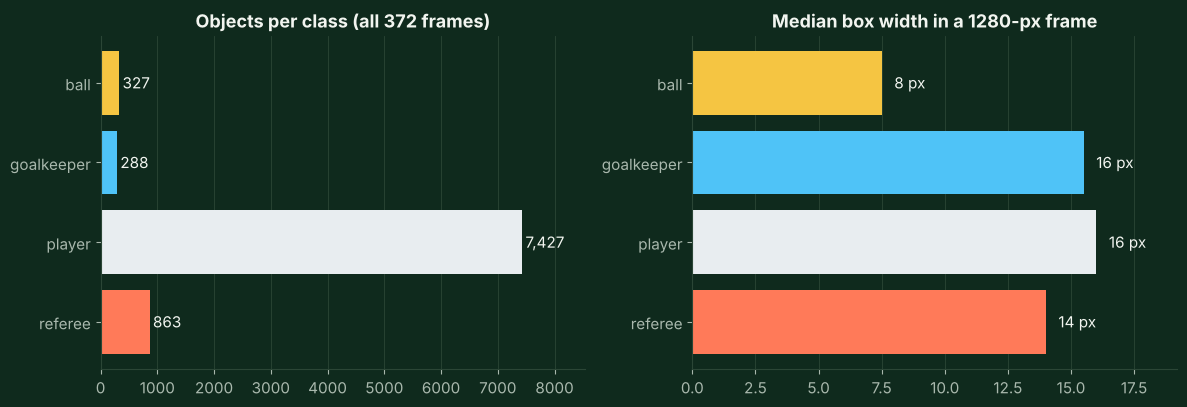

Players outnumber balls 23 to 1, and the median ball is 8 px wide (0.6% of the frame).


In [3]:
counts = labels.cls.value_counts().reindex(CLASSES)
size = labels.groupby('cls').w_px.median().reindex(CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh(CLASSES, counts, color=[CLS_COL[c] for c in CLASSES])
for i, v in enumerate(counts): ax[0].text(v + 60, i, f'{v:,}', va='center', color=INK)
ax[0].set_title('Objects per class (all 372 frames)'); ax[0].grid(axis='y', visible=False); ax[1].grid(axis='y', visible=False); ax[0].set_xlim(0, counts.max() * 1.15); ax[0].invert_yaxis()
ax[1].barh(CLASSES, size, color=[CLS_COL[c] for c in CLASSES])
for i, v in enumerate(size): ax[1].text(v + 0.5, i, f'{v:.0f} px', va='center', color=INK)
ax[1].set_title('Median box width in a 1280-px frame'); ax[1].set_xlim(0, size.max() * 1.2); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig(CHARTS / '01_class_balance_and_size.png'); plt.show()
print(f"Players outnumber balls {counts['player'] / counts['ball']:.0f} to 1, and the median ball is "
      f"{size['ball']:.0f} px wide ({size['ball'] / 1280:.1%} of the frame).")

**What this means.** The data is heavily imbalanced: players make up 83% of all labels, while the ball appears at most once per frame. The ball is also tiny, roughly 7 pixels wide in a 1280-pixel frame. Both point to the ball being the hardest class, so it is reported separately throughout.

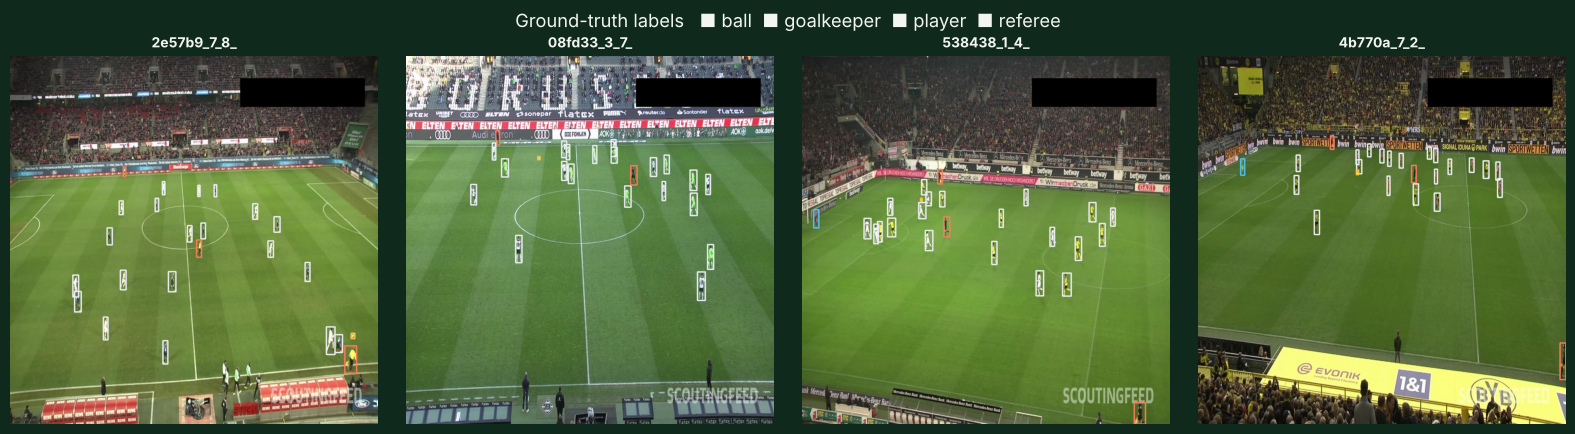

In [4]:
def draw(img, boxes, names, thickness=2):
    for (x1, y1, x2, y2), n in zip(boxes, names):
        col = tuple(int(CLS_COL[n].lstrip('#')[i:i+2], 16) for i in (4, 2, 0))   # hex -> BGR
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), col, thickness)
    return img

def gt_boxes(img_path):
    lf = img_path.parent.parent / 'labels' / (img_path.stem + '.txt')
    b, n = [], []
    for line in lf.read_text().split('\n'):
        if line.strip():
            c, x, y, w, h = map(float, line.split())
            b.append(((x - w/2) * 1280, (y - h/2) * 1280, (x + w/2) * 1280, (y + h/2) * 1280)); n.append(CLASSES[int(c)])
    return b, n

samples = random.sample(sorted((DATA / 'train' / 'images').glob('*.jpg')), 4)
fig, axs = plt.subplots(1, 4, figsize=(16, 4.4))
for a, p in zip(axs, samples):
    img = cv2.imread(str(p)); b, n = gt_boxes(p)
    a.imshow(cv2.cvtColor(draw(img, b, n, 4), cv2.COLOR_BGR2RGB)); a.axis('off'); a.set_title(p.stem[:11], fontsize=10)
plt.suptitle('Ground-truth labels   ■ ball  ■ goalkeeper  ■ player  ■ referee', color=INK)
plt.tight_layout(); plt.savefig(CHARTS / '02_ground_truth_samples.png'); plt.show()

## 3. Training
YOLOv8n is the smallest YOLOv8 model. It was chosen because it trains and runs on a laptop CPU in reasonable time; the trade-off is lower accuracy on tiny objects than the larger variants.

* Start from COCO-pretrained weights (transfer learning), so the model already recognises "person" and "sports ball".
* Images are resized to 640 px. This is roughly 4× faster than training at full resolution, but it halves the ball to about 3–4 px. This is the main accuracy trade-off.
* Ultralytics' default augmentation (mosaic, HSV jitter, flips, scaling) is kept on.
* A fixed time budget (1.75 h on 2 CPU cores) is used, and the best epoch by validation fitness is kept.

The cell below trains only if no trained weights exist yet, so the notebook can be rerun quickly.

In [5]:
TRAIN_ARGS = dict(data=str(DATA / 'data.yaml'), epochs=60, time=1.75, imgsz=640, batch=8, device='cpu',
                  workers=2, cache='ram', seed=42, project=str(RUN_DIR.parent), name=RUN_DIR.name, exist_ok=True)
best = RUN_DIR / 'weights' / 'best.pt'
if not best.exists():
    YOLO('yolov8n.pt').train(**TRAIN_ARGS)
model = YOLO(str(best))
hist = pd.read_csv(RUN_DIR / 'results.csv'); hist.columns = hist.columns.str.strip()
print(f'Trained for {len(hist)} epochs ({hist["time"].iloc[-1] / 3600:.2f} h on CPU)')
print(f'Best validation mAP50 {hist["metrics/mAP50(B)"].max():.3f} at epoch {int(hist.loc[hist["metrics/mAP50(B)"].idxmax(), "epoch"])}')

Trained for 43 epochs (1.75 h on CPU)
Best validation mAP50 0.767 at epoch 43


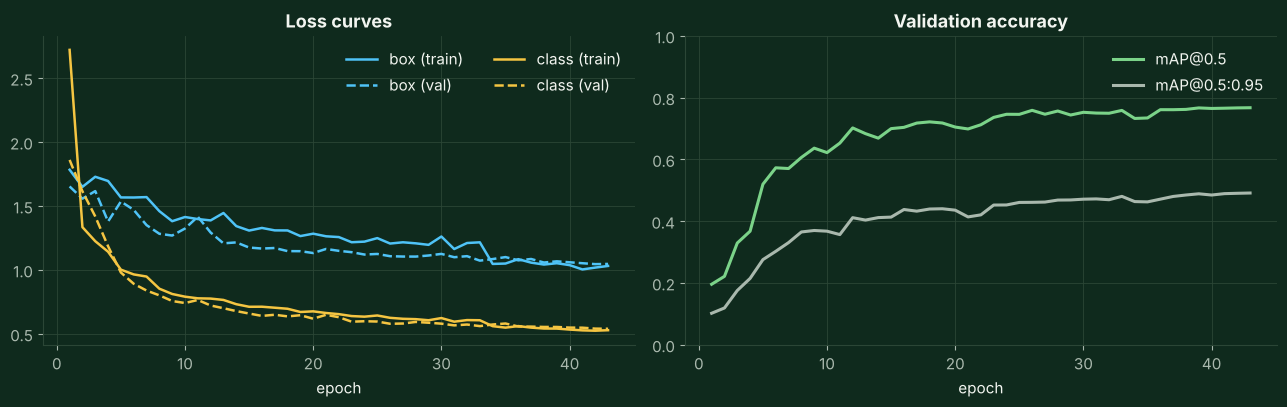

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for col, lab, c in [('train/box_loss', 'box (train)', '#4fc3f7'), ('val/box_loss', 'box (val)', '#4fc3f7'),
                    ('train/cls_loss', 'class (train)', '#f5c542'), ('val/cls_loss', 'class (val)', '#f5c542')]:
    ax[0].plot(hist.epoch, hist[col], label=lab, color=c, ls='--' if 'val' in col else '-', lw=1.8)
ax[0].set_title('Loss curves'); ax[0].set_xlabel('epoch'); ax[0].legend(frameon=False, ncol=2)
ax[1].plot(hist.epoch, hist['metrics/mAP50(B)'], color='#7bd389', lw=2.2, label='mAP@0.5')
ax[1].plot(hist.epoch, hist['metrics/mAP50-95(B)'], color='#a9b8ad', lw=2.2, label='mAP@0.5:0.95')
ax[1].set_title('Validation accuracy'); ax[1].set_xlabel('epoch'); ax[1].set_ylim(0, 1); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(CHARTS / '03_training_curves.png'); plt.show()

## 4. Choosing the inference resolution (on validation data)
The model was trained on 640-px images, but at prediction time it can be fed larger images. More pixels should help the tiny ball, at the cost of speed. The resolution is chosen on the **validation** split only, so the test set stays untouched until the final evaluation.

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon Processor @ 2.10GHz)


Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1336.0±298.2 MB/s, size: 181.2 KB)


val: Scanning ../data/valid/labels.cache... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 8.9Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 7% ╸─────────── 1/13 2.0s/it 0.6s<23.5s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 15% ━╸────────── 2/13 1.0s/it 1.1s<11.4s

... (49 outputs left out)

                   all         49       1174      0.666      0.649       0.71       0.44


Speed: 18.8ms preprocess, 529.4ms inference, 0.0ms loss, 2.8ms postprocess per image


,imgsz,mAP50_all,mAP50_ball,recall_ball,mAP50_95_all,ms_per_frame
0,640,0.768,0.287,0.289,0.491,110.788
1,960,0.806,0.432,0.378,0.542,280.060
2,1280,0.710,0.325,0.333,0.440,529.427


Chosen inference size: 960 px


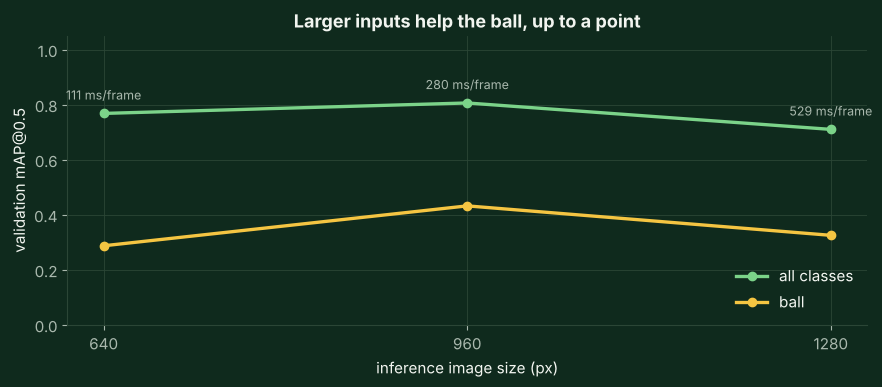

In [7]:
sweep = []
for sz in [640, 960, 1280]:
    r = model.val(data=str(DATA / 'data.yaml'), split='val', imgsz=sz, batch=4, device='cpu', plots=False,
                  verbose=False, project=str(OUT), name='val_sweep', exist_ok=True)
    sweep.append(dict(imgsz=sz, mAP50_all=r.box.map50, mAP50_ball=r.box.ap50[0], recall_ball=r.box.r[0],
                      mAP50_95_all=r.box.map, ms_per_frame=r.speed['inference']))
sweep = pd.DataFrame(sweep).round(3); display(sweep)
IMGSZ = int(sweep.loc[sweep.mAP50_all.idxmax(), 'imgsz'])
print(f'Chosen inference size: {IMGSZ} px')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sweep.imgsz, sweep.mAP50_all, 'o-', color='#7bd389', lw=2.4, label='all classes')
ax.plot(sweep.imgsz, sweep.mAP50_ball, 'o-', color='#f5c542', lw=2.4, label='ball')
for _, r in sweep.iterrows():
    ax.annotate(f"{r.ms_per_frame:.0f} ms/frame", (r.imgsz, r.mAP50_all), textcoords='offset points', xytext=(0, 10), ha='center', color=MUTED, fontsize=9)
ax.set_xticks(sweep.imgsz); ax.set_xlabel('inference image size (px)'); ax.set_ylabel('validation mAP@0.5'); ax.set_ylim(0, 1.05)
ax.set_title('Larger inputs help the ball, up to a point'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig(CHARTS / '04a_resolution_sweep.png'); plt.show()

**Why 1280 is worse than 960.** At 1280 px every object appears twice as large as anything the model saw in training. Players and goalkeepers start to fall outside the size range it learned, so accuracy drops. 960 px balances helping the ball against staying close to the training scale.

## 5. Evaluation on the held-out test set
The test split (25 frames) was not used for training, model selection or the resolution choice. The 640-px result is shown as a baseline.

In [8]:
base = model.val(data=str(DATA / 'data.yaml'), split='test', imgsz=640, batch=4, device='cpu', plots=False,
                 verbose=False, project=str(OUT), name='test_640', exist_ok=True)
res = model.val(data=str(DATA / 'data.yaml'), split='test', imgsz=IMGSZ, batch=4, device='cpu',
                plots=True, project=str(OUT), name='test_eval', exist_ok=True, verbose=False)
per_class = pd.DataFrame({
    'class': CLASSES,
    'instances': [int((labels.split.eq('test') & labels.cls.eq(c)).sum()) for c in CLASSES],
    'precision': res.box.p, 'recall': res.box.r, 'mAP50': res.box.ap50, 'mAP50-95': res.box.ap})
overall = pd.DataFrame([{'class': 'all', 'instances': per_class.instances.sum(), 'precision': res.box.mp,
                         'recall': res.box.mr, 'mAP50': res.box.map50, 'mAP50-95': res.box.map}])
test_table = pd.concat([per_class, overall], ignore_index=True).round(3)
print(f'Test mAP50 at 640 px (baseline): {base.box.map50:.3f}  |  at {IMGSZ} px: {res.box.map50:.3f}')
test_table.to_csv(OUT / 'test_metrics.csv', index=False)
test_table

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon Processor @ 2.10GHz)


Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3992.1±1218.4 MB/s, size: 175.5 KB)


val: Scanning ../data/test/labels.cache... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 9.5Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 1/7 1.7s/it 0.5s<9.9s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 28% ━━━───────── 2/7 1.0s/it 1.0s<5.0s

... (19 outputs left out)

Speed: 11.5ms preprocess, 279.3ms inference, 0.0ms loss, 1.4ms postprocess per image


Results saved to ../outputs/test_eval


Test mAP50 at 640 px (baseline): 0.787  |  at 960 px: 0.826


,class,instances,precision,recall,mAP50,mAP50-95
0,ball,24,0.946,0.375,0.426,0.176
1,goalkeeper,19,0.937,0.779,0.931,0.719
2,player,499,0.979,0.968,0.992,0.785
3,referee,56,0.925,0.875,0.954,0.634
4,all,598,0.947,0.749,0.826,0.579


,v1 Roboflow 3.0,v2 YOLOv8n (this notebook)
class,,
ball,0.47,0.426
goalkeeper,0.91,0.931
player,0.98,0.992
referee,0.91,0.954
all,0.82,0.826


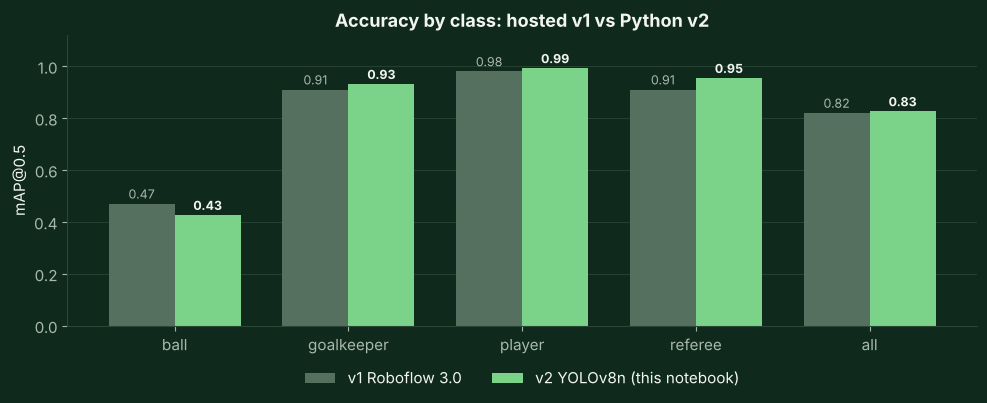

In [9]:
v1 = {'ball': 0.47, 'goalkeeper': 0.91, 'player': 0.98, 'referee': 0.91, 'all': 0.82}   # Roboflow 3.0 model (v1), mAP50 from its dashboard
cmp = test_table.set_index('class')[['mAP50']].rename(columns={'mAP50': 'v2 YOLOv8n (this notebook)'})
cmp['v1 Roboflow 3.0'] = pd.Series(v1)
cmp = cmp[['v1 Roboflow 3.0', 'v2 YOLOv8n (this notebook)']]
display(cmp)
x = np.arange(len(cmp)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(x - w/2, cmp.iloc[:, 0], w, color='#55705f', label=cmp.columns[0])
ax.bar(x + w/2, cmp.iloc[:, 1], w, color='#7bd389', label=cmp.columns[1])
for i, (a, b) in enumerate(cmp.values):
    ax.text(i - w/2, a + 0.02, f'{a:.2f}', ha='center', color=MUTED, fontsize=9)
    ax.text(i + w/2, b + 0.02, f'{b:.2f}', ha='center', color=INK, fontsize=9, fontweight='bold')
ax.set_xticks(x, cmp.index); ax.set_ylim(0, 1.12); ax.grid(axis='x', visible=False); ax.set_ylabel('mAP@0.5'); ax.legend(frameon=False, loc='upper center', ncol=2, bbox_to_anchor=(0.5, -0.1))
ax.set_title('Accuracy by class: hosted v1 vs Python v2')
plt.tight_layout(); plt.savefig(CHARTS / '04_v1_vs_v2_by_class.png'); plt.show()

*Caveat on the comparison:* v1's figures come from Roboflow's dashboard (its own validation split), while v2 is scored on the test split here. Treat this as a rough comparison, not a controlled experiment.

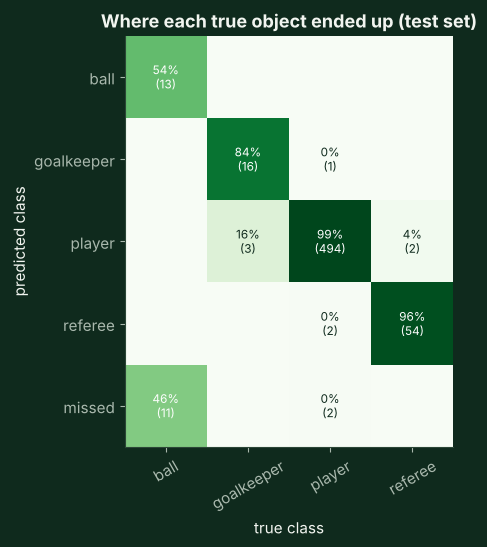

In [10]:
cm = res.confusion_matrix.matrix[:, :4]     # rows = predicted (+ background = missed), cols = true class
rows = CLASSES + ['missed']
cmn = cm / np.clip(cm.sum(0, keepdims=True), 1, None)
fig, ax = plt.subplots(figsize=(5.6, 5.6)); ax.grid(False)
ax.imshow(cmn, cmap='Greens', vmin=0, vmax=1)
for i in range(5):
    for j in range(4):
        if cm[i, j] > 0:
            ax.text(j, i, f'{cmn[i, j]:.0%}\n({int(cm[i, j])})', ha='center', va='center', fontsize=8.5,
                    color='white' if cmn[i, j] > 0.45 else '#0f2a1d')
ax.set_xticks(range(4), CLASSES, rotation=30); ax.set_yticks(range(5), rows)
ax.set_xlabel('true class'); ax.set_ylabel('predicted class'); ax.set_title('Where each true object ended up (test set)')
plt.tight_layout(); plt.savefig(CHARTS / '05_confusion_matrix.png'); plt.show()

In [11]:
# Inference speed on CPU
test_imgs = sorted((DATA / 'test' / 'images').glob('*.jpg'))
model.predict(str(test_imgs[0]), imgsz=IMGSZ, device='cpu', verbose=False)          # warm-up
t0 = time.perf_counter()
for p in test_imgs: model.predict(str(p), imgsz=IMGSZ, device='cpu', verbose=False)
ms = (time.perf_counter() - t0) / len(test_imgs) * 1000
print(f'{ms:.0f} ms per frame at {IMGSZ} px on a 2-core CPU  ->  ~{1000 / ms:.1f} frames per second (no GPU)')

244 ms per frame at 960 px on a 2-core CPU  ->  ~4.1 frames per second (no GPU)


## 6. Predictions vs ground truth

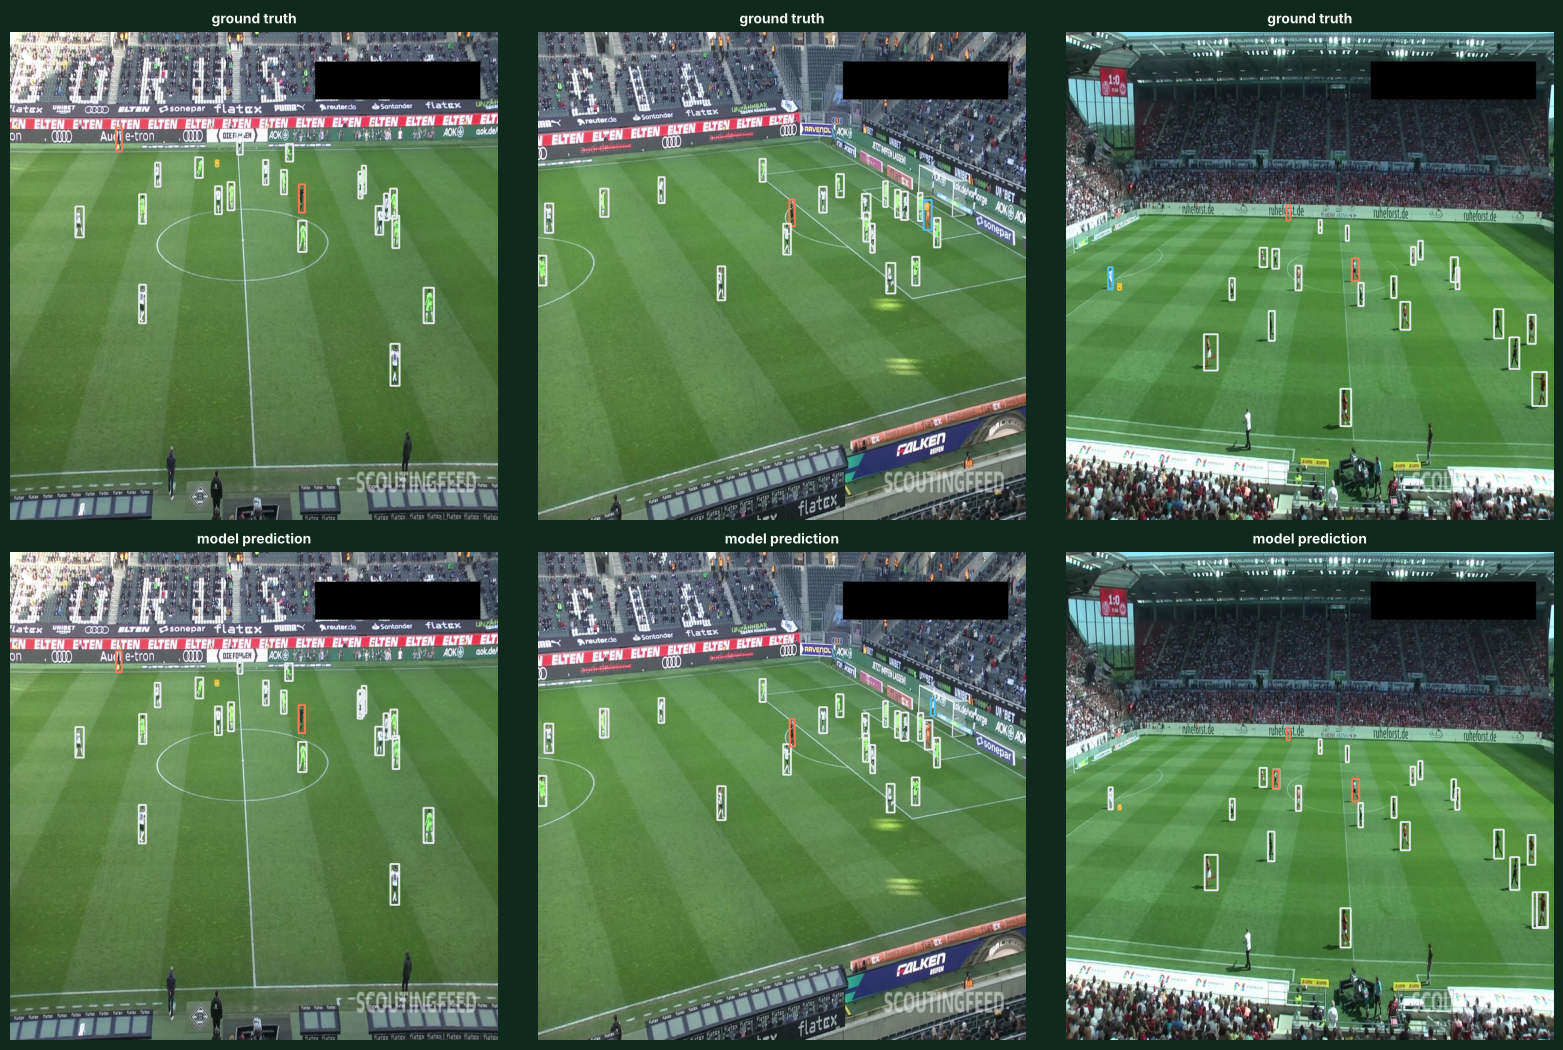

In [12]:
picks = test_imgs[:3]
fig, axs = plt.subplots(2, 3, figsize=(16, 10.6))
for k, p in enumerate(picks):
    img = cv2.imread(str(p)); b, n = gt_boxes(p)
    axs[0, k].imshow(cv2.cvtColor(draw(img.copy(), b, n, 3), cv2.COLOR_BGR2RGB)); axs[0, k].set_title('ground truth', fontsize=10)
    r = model.predict(str(p), imgsz=IMGSZ, conf=0.25, device='cpu', verbose=False)[0]
    pb = r.boxes.xyxy.numpy(); pn = [CLASSES[int(c)] for c in r.boxes.cls]
    axs[1, k].imshow(cv2.cvtColor(draw(img.copy(), pb, pn, 3), cv2.COLOR_BGR2RGB)); axs[1, k].set_title('model prediction', fontsize=10)
for a in axs.flat: a.axis('off')
plt.tight_layout(); plt.savefig(CHARTS / '06_predictions_vs_truth.png'); plt.show()

## 7. From detections to match analytics
A detector only produces boxes. To get information a coach or analyst can use, two steps are added on top.

**7a. Team identification.** For each detected player, take a small patch from the centre of the shirt, which contains almost no grass, and compute its median colour. Within each clip, k-means with *k* = 2 splits the players into two teams. No labels are needed, so this works for any kit colours.

**7b. Possession proxy.** In each frame where the ball is detected, the team of the player whose feet are closest to the ball is counted as in possession, provided that player is within 1.5 body-heights of the ball. Otherwise the frame is counted as *loose ball*.

In [13]:
from sklearn.cluster import KMeans

def jersey_colour(img, box):
    # Median colour (Lab) of the centre of the shirt. Using only the central patch keeps grass out
    # without filtering by colour, so green kits are not thrown away.
    x1, y1, x2, y2 = map(int, box)
    w, h = x2 - x1, y2 - y1
    crop = img[y1 + int(0.18 * h): y1 + int(0.45 * h), x1 + int(0.3 * w): x2 - int(0.3 * w)]
    if crop.size < 6: return None
    return np.median(cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).reshape(-1, 3), axis=0)

all_imgs = sorted(DATA.glob('*/images/*.jpg'))
dets = []
for p in all_imgs:
    r = model.predict(str(p), imgsz=IMGSZ, conf=0.25, device='cpu', verbose=False)[0]
    img = cv2.imread(str(p))
    for (x1, y1, x2, y2), c, s in zip(r.boxes.xyxy.numpy(), r.boxes.cls.numpy(), r.boxes.conf.numpy()):
        name = CLASSES[int(c)]
        dets.append(dict(image=p.stem, split=p.parent.parent.name, clip='_'.join(p.stem.split('_')[:2]),
                         frame=int(p.stem.split('_')[2]), cls=name, conf=float(s), x1=x1, y1=y1, x2=x2, y2=y2,
                         colour=jersey_colour(img, (x1, y1, x2, y2)) if name == 'player' else None))
dets = pd.DataFrame(dets)
print(f'{len(dets):,} detections across {dets['image'].nunique()} frames and {dets['clip'].nunique()} clips')

9,552 detections across 372 frames and 56 clips


In [14]:
dets['team'] = pd.Series([None] * len(dets), dtype=object, index=dets.index)
for clip, g in dets[dets.cls.eq('player') & dets.colour.notna()].groupby('clip'):
    X = np.stack(g.colour.values)
    km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X)
    lab = km.labels_
    if km.cluster_centers_[0, 0] < km.cluster_centers_[1, 0]: lab = 1 - lab    # Team A = lighter shirts
    dets.loc[g.index, 'team'] = np.where(lab == 0, 'A', 'B')
team_sizes = dets[dets.team.notna()].groupby(['image', 'team']).size().unstack(fill_value=0)
print('Median players per team per frame:', team_sizes.median().to_dict())

Median players per team per frame: {'A': 10.0, 'B': 11.0}


In [15]:
def possession(frame_dets):
    ball = frame_dets[frame_dets.cls.eq('ball')].sort_values('conf', ascending=False)
    pl = frame_dets[frame_dets.team.notna()]
    if ball.empty or pl.empty: return 'no ball detected'
    b = ball.iloc[0]; bx, by = (b.x1 + b.x2) / 2, (b.y1 + b.y2) / 2
    feet_x, feet_y = (pl.x1 + pl.x2) / 2, pl.y2
    d = np.hypot(feet_x - bx, feet_y - by); i = d.idxmin()
    return f'Team {pl.loc[i, "team"]}' if d[i] < 1.5 * (pl.loc[i, 'y2'] - pl.loc[i, 'y1']) else 'loose ball'

poss = dets.groupby('image').apply(possession).rename('possession').reset_index()
poss['clip'] = poss['image'].str.split('_').str[:2].str.join('_')
share = poss.possession.value_counts(normalize=True).reindex(['Team A', 'Team B', 'loose ball', 'no ball detected']).fillna(0)
print((share * 100).round(1).astype(str) + '%')
poss.to_csv(OUT / 'possession_by_frame.csv', index=False)

possession
Team A              16.1%
Team B              23.7%
loose ball           7.5%
no ball detected    52.7%
Name: proportion, dtype: str


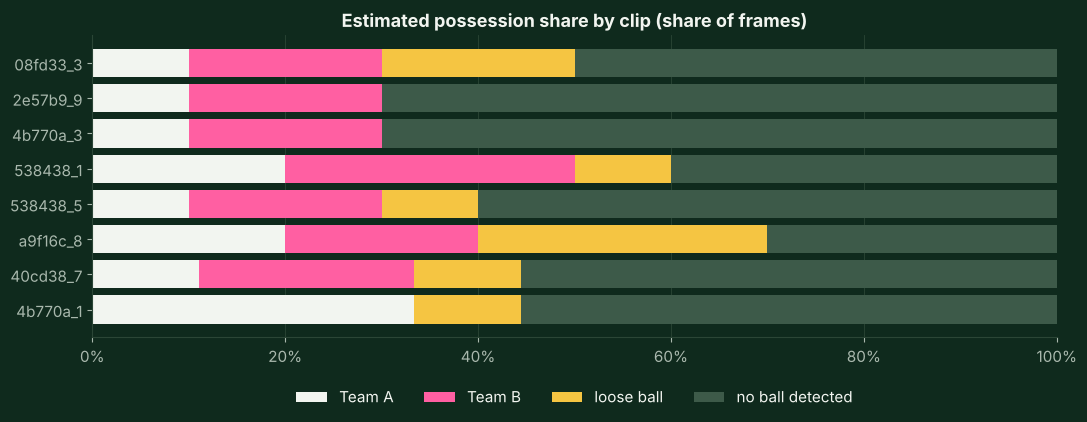

In [16]:
# Possession by clip for the clips with the most frames
top = poss['clip'].value_counts().head(8).index
tab = poss[poss['clip'].isin(top)].groupby('clip').possession.value_counts(normalize=True).unstack(fill_value=0)
tab = tab.reindex(columns=['Team A', 'Team B', 'loose ball', 'no ball detected'], fill_value=0).loc[top]
cols = {'Team A': TEAM_COL['A'], 'Team B': TEAM_COL['B'], 'loose ball': '#f5c542', 'no ball detected': '#3d5a49'}
fig, ax = plt.subplots(figsize=(11, 4.4)); left = np.zeros(len(tab))
for c in tab.columns:
    ax.barh(tab.index, tab[c], left=left, color=cols[c], label=c); left += tab[c].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.invert_yaxis()
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12)); ax.grid(axis='y', visible=False)
ax.set_title('Estimated possession share by clip (share of frames)')
plt.tight_layout(); plt.savefig(CHARTS / '07_possession_by_clip.png'); plt.show()

### Annotated output
Team A in white, Team B in pink, goalkeepers in blue, referees in orange and the ball in yellow. The banner shows the possession call for the frame.

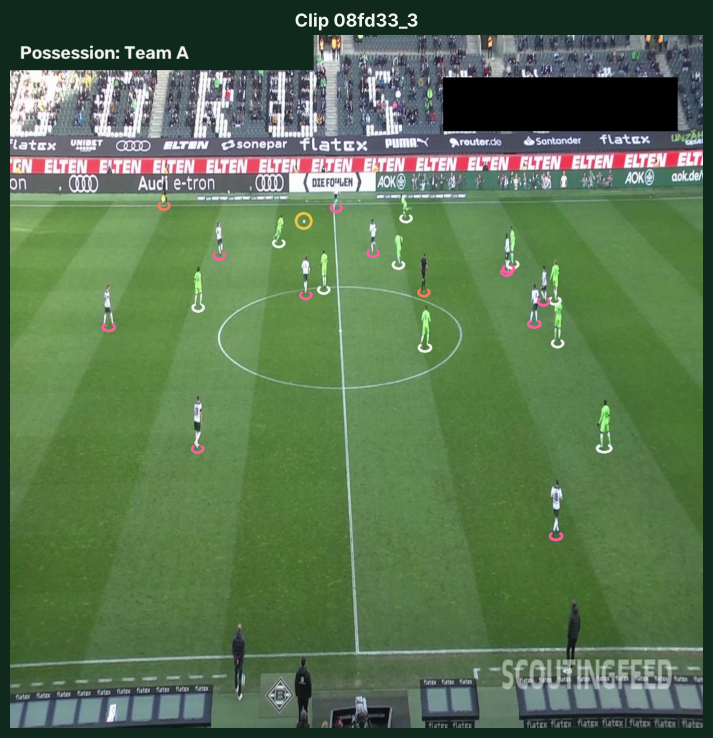

GIF of 10 frames from clip 08fd33_3 saved to outputs/match_analytics.gif


In [17]:
TEAM_BGR = {t: hex2bgr(c) for t, c in TEAM_COL.items()}
def annotate(stem):
    p = next(DATA.glob(f'*/images/{stem}.jpg')); img = cv2.imread(str(p)); f = dets[dets['image'].eq(stem)]
    for _, d in f.iterrows():
        x1, y1, x2, y2 = map(int, (d.x1, d.y1, d.x2, d.y2))
        if d.cls == 'ball':
            cv2.circle(img, ((x1 + x2) // 2, (y1 + y2) // 2), 14, hex2bgr(CLS_COL['ball']), 3)
        elif d.cls == 'player' and isinstance(d.team, str):
            cv2.ellipse(img, ((x1 + x2) // 2, y2), (max((x2 - x1) // 2, 10), 7), 0, -45, 225, TEAM_BGR[d.team], 3)
        else:
            col = hex2bgr(CLS_COL['referee'] if d.cls == 'referee' else CLS_COL['goalkeeper'])
            cv2.ellipse(img, ((x1 + x2) // 2, y2), (max((x2 - x1) // 2, 10), 7), 0, -45, 225, col, 3)
    label = poss.set_index('image').possession.get(stem, '')
    cv2.rectangle(img, (0, 0), (560, 64), (29, 42, 15), -1)
    cv2.putText(img, f'Possession: {label}', (18, 44), cv2.FONT_HERSHEY_SIMPLEX, 1.15, (240, 245, 242), 2, cv2.LINE_AA)
    return img

clip = poss['clip'].value_counts().index[0]
seq = dets[dets['clip'].eq(clip)].drop_duplicates('image').sort_values('frame').image.tolist()
frames = [cv2.cvtColor(annotate(s), cv2.COLOR_BGR2RGB) for s in seq]
cv2.imwrite(str(OUT / 'annotated_frame.jpg'), cv2.cvtColor(frames[len(frames) // 2], cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 88])
import imageio.v2 as imageio
imageio.mimsave(OUT / 'match_analytics.gif', [cv2.resize(f, (720, 720)) for f in frames], duration=900, loop=0)
plt.figure(figsize=(9, 9)); plt.imshow(frames[len(frames) // 2]); plt.axis('off'); plt.title(f'Clip {clip}'); plt.show()
print(f'GIF of {len(frames)} frames from clip {clip} saved to outputs/match_analytics.gif')

## 8. Limitations and next steps
* **Optimistic test scores.** Frames were sampled from about 55 short clips, and frames from the same clip appear in train, validation and test. Test frames are therefore similar to frames the model has already seen. A stricter evaluation would hold out entire matches.
* **The ball is still the bottleneck.** Predicting at 960 px helps, but the model still misses more than half of balls. Options: train at 1280 px on a GPU, use a larger model (YOLOv8s/m), or crop around the last known ball position (tiling or SAHI).
* **Possession is a proxy.** It counts frames, not seconds, and "closest player" is not always the player in control. Adding tracking (ByteTrack) and a pitch homography would allow possession over time, distance covered and heatmaps in metres.
* **Team split per clip.** k-means sees only shirt colour, so referees or goalkeepers with similar kits can confuse it. Goalkeepers and referees are detected as separate classes for this reason.